In [1]:
import pandas as pd
import numpy as np

# Chargement de la base nettoyée
df = pd.read_parquet(
    "../data/processed/online_retail_II_cleaned.parquet"
)

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (777622, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Montant
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [2]:
# Vérification de la période des transactions
print("Type de InvoiceDate :", df["InvoiceDate"].dtype)

print("Première transaction :", df["InvoiceDate"].min())
print("Dernière transaction :", df["InvoiceDate"].max())

# Date de référence pour le calcul de Recency
date_reference = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Date de référence :", date_reference)

Type de InvoiceDate : datetime64[ns]
Première transaction : 2009-12-01 07:45:00
Dernière transaction : 2011-12-09 12:50:00
Date de référence : 2011-12-10 12:50:00


In [3]:
# Agrégation des transactions au niveau client

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (date_reference - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Montant", "sum")
).reset_index()

# Affichage des premières lignes
display(rfm.head(10))

print("Dimensions de la table RFM :", rfm.shape)
print("Nombre de clients :", rfm["Customer ID"].nunique())

,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,1658.40
3,12349.0,19,3,3678.69
4,12350.0,310,1,294.40
5,12351.0,375,1,300.93
6,12352.0,36,10,2569.84
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61


Dimensions de la table RFM : (5877, 4)
Nombre de clients : 5877


In [4]:
# Statistiques descriptives des variables RFM
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

,Recency,Frequency,Monetary
count,5877.000000,5877.000000,5877.000000
mean,201.276161,6.271737,2935.197589
std,209.246679,12.973247,14410.995888
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,340.500000
50%,96.000000,3.000000,856.010000
75%,380.000000,7.000000,2243.090000
max,739.000000,398.000000,580987.040000


Recency : la moitié des clients n'a pas effectué d'achat depuis au moins 96 jours.
Frequency : la majorité des clients passent relativement peu de commandes.
Monetary : certains clients dépensent beaucoup plus que les autres. Le maximum de 580 987,04 est très éloigné de la médiane de 856,01.

In [5]:
# Enregistrement de la table RFM
chemin_rfm = "../data/processed/customer_rfm.parquet"

rfm.to_parquet(chemin_rfm, index=False)

print("Table RFM enregistrée !")
print("Dimensions :", rfm.shape)

Table RFM enregistrée !
Dimensions : (5877, 4)


## 3. Analyse de la distribution des variables RFM

Avant d'appliquer les transformations, nous analysons la distribution
des variables Recency, Frequency et Monetary afin d'identifier
une éventuelle asymétrie.

Coefficient d'asymétrie des variables RFM :


,Skewness
Recency,0.886869
Frequency,12.653739
Monetary,25.126984


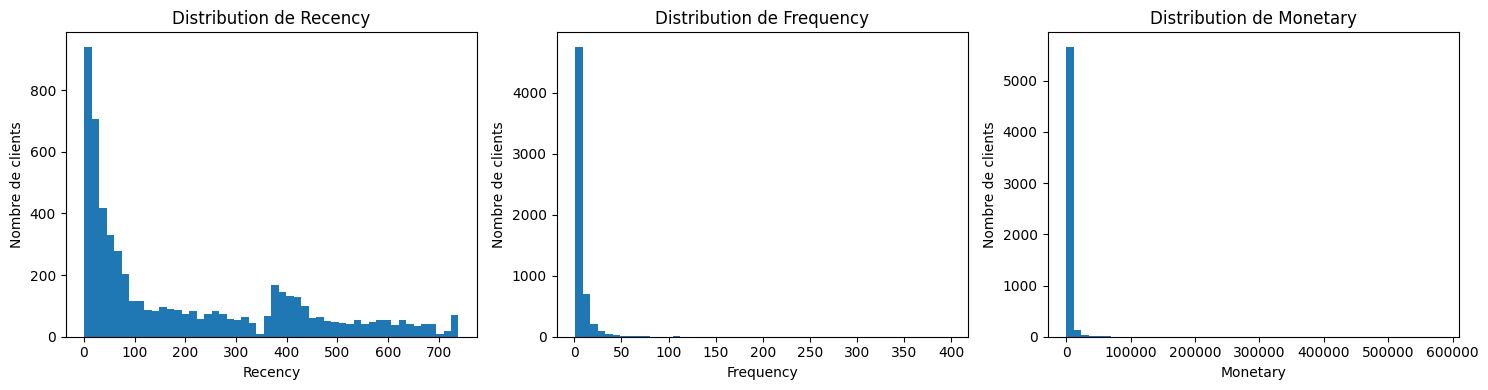

In [6]:
import matplotlib.pyplot as plt
from scipy.stats import skew

# Calcul de l'asymétrie des variables RFM
asymetrie = rfm[["Recency", "Frequency", "Monetary"]].skew()

print("Coefficient d'asymétrie des variables RFM :")
display(asymetrie.to_frame(name="Skewness"))

# Visualisation des distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, colonne in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(rfm[colonne], bins=50)
    ax.set_title(f"Distribution de {colonne}")
    ax.set_xlabel(colonne)
    ax.set_ylabel("Nombre de clients")

plt.tight_layout()
plt.show()

## 4. Transformation logarithmique

Les variables RFM présentent des distributions asymétriques.
Nous appliquons la transformation log(1+x) afin de réduire
l'influence des valeurs extrêmes et de limiter l'asymétrie.

In [7]:
# Création d'une copie de la table RFM
rfm_log = rfm.copy()

# Application de log(1+x) aux variables RFM
colonnes_rfm = ["Recency", "Frequency", "Monetary"]

for colonne in colonnes_rfm:
    rfm_log[colonne] = np.log1p(rfm_log[colonne])

# Vérification des résultats
display(rfm_log.head())

# Comparaison de l'asymétrie avant et après transformation
comparaison = pd.DataFrame({
    "Avant transformation": rfm[colonnes_rfm].skew(),
    "Après transformation": rfm_log[colonnes_rfm].skew()
})

display(comparaison)

,Customer ID,Recency,Frequency,Monetary
0,12346.0,5.789960,2.564949,11.258774
1,12347.0,1.098612,2.197225,8.501578
2,12348.0,4.330733,1.791759,7.414211
3,12349.0,2.995732,1.386294,8.210584
4,12350.0,5.739793,0.693147,5.688330


,Avant transformation,Après transformation
Recency,0.886869,-0.488938
Frequency,12.653739,1.002938
Monetary,25.126984,0.271442


Les résultats sont très satisfaisants :
- Recency : l'asymétrie positive devient légèrement négative.
- Frequency : la forte asymétrie passe de 12,65 à environ 1.
- Monetary : passe de 25,13 à 0,27, ce qui indique une distribution relativement équilibrée.
La transformation logarithmique a donc considérablement réduit l'influence des valeurs extrêmes.

## 5. Standardisation des variables RFM

Nous appliquons la standardisation Z-score pour obtenir
des variables de moyenne 0 et d'écart-type 1.

In [8]:
from sklearn.preprocessing import StandardScaler

# Séparer les identifiants des variables utilisées pour le clustering
X = rfm_log[colonnes_rfm]

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Création du DataFrame standardisé
rfm_scaled = pd.DataFrame(
    X_scaled,
    columns=colonnes_rfm,
    index=rfm.index
)

# Conserver l'identifiant client
rfm_scaled.insert(0, "Customer ID", rfm["Customer ID"].values)

display(rfm_scaled.head())

# Vérification de la moyenne et de l'écart-type
display(rfm_scaled[colonnes_rfm].agg(["mean", "std"]).T)

,Customer ID,Recency,Frequency,Monetary
0,12346.0,0.856824,1.257733,3.213764
1,12347.0,-2.152211,0.803120,1.222615
2,12348.0,-0.079125,0.301849,0.437357
3,12349.0,-0.935396,-0.199422,1.012469
4,12350.0,0.824647,-1.056350,-0.809013


,mean,std
Recency,4.594287e-17,1.000085
Frequency,-7.435491e-17,1.000085
Monetary,3.675429e-16,1.000085


Les trois variables sont maintenant sur une échelle comparable. Elles peuvent être utilisées comme entrées de K-Means.

In [9]:
from pathlib import Path
import joblib

# Chemin du dossier de sauvegarde
dossier_processed = Path("../data/processed")

if not dossier_processed.exists():
    dossier_processed = Path("data/processed")

dossier_processed.mkdir(parents=True, exist_ok=True)

# Sauvegarder les tables
rfm.to_parquet(
    dossier_processed / "customer_rfm.parquet",
    index=False
)

rfm_scaled.to_parquet(
    dossier_processed / "customer_rfm_scaled.parquet",
    index=False
)

# Sauvegarder le scaler pour les futures prédictions
joblib.dump(
    scaler,
    dossier_processed / "rfm_scaler.joblib"
)

print("Données RFM et scaler sauvegardés avec succès.")

Données RFM et scaler sauvegardés avec succès.
